## Notebook 05: Explainable AI (SHAP) Interpretability

---

### 1. Architectural Role & Project Context
In disaster response and emergency water management, **black-box predictions are operationally unacceptable**. Emergency Operations Centers (EOC) commanders and municipal water authorities must understand:
1. **Global Attributions**: Which hydrological, operational, and network features dominate decision-making system-wide?
2. **Local Attributions**: Exactly *why* a specific scenario was classified as P1 Critical vs P2 High (e.g. was it driven by toxic concentration, vulnerable population, or a LoRa telemetry blackout?).

This notebook uses **TreeSHAP (SHapley Additive exPlanations)** to compute game-theoretically grounded feature attributions for the champion production model.

---

### 2. Linked Source Scripts (`src/component04_ml/`)
- **`src/component04_ml/explainability.py`**:
  - `DecisionModelExplainer`: Wraps `shap.TreeExplainer` for high-speed exact Shapley calculation on tree ensembles.
  - `generate_summary_plots(X_sample)`: Saves global beeswarm and bar importance figures to `artifacts/figures/`.
  - `explain_instance(x_scaled, top_k)`: Decomposes individual scenario predictions into ranked positive and negative driving factors.
- **`src/component04_ml/preprocessing.py`**:
  - `DecisionDataPreprocessor`: Loads `models/preprocessor.joblib` to maintain feature schema alignment and feature names.


In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

root_dir = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(root_dir) not in sys.path:
    sys.path.insert(0, str(root_dir))

from src.component04_ml.preprocessing import DecisionDataPreprocessor
from src.component04_ml.explainability import DecisionModelExplainer

models_dir = root_dir / "models"
test_df = pd.read_csv(root_dir / "data" / "processed" / "test_scenarios.csv")

preprocessor = DecisionDataPreprocessor.load(models_dir / "preprocessor.joblib")
model = joblib.load(models_dir / "selected_model.joblib")

explainer = DecisionModelExplainer(model, preprocessor.fitted_feature_names)
print("Explainer initialized successfully.")


Explainer initialized successfully.


### Section 1: Global Feature Importance & Summary Plots (TreeSHAP)
**Source Module:** `src/component04_ml/explainability.py` -> `DecisionModelExplainer.generate_summary_plots()`

#### TreeSHAP Foundations:
TreeSHAP computes exact Shapley values in polynomial time $\mathcal{O}(T L D^2)$ rather than exponential time. For a scenario $x$:
$$f(x) = \phi_0 + \sum_{i=1}^M \phi_i(x)$$
where $\phi_0$ is the base expected value and $\phi_i$ is the marginal contribution of feature $i$.
- **Beeswarm Plot**: Shows the directionality (high vs low feature value) and magnitude of each feature's impact on priority assignment.
- **Bar Plot**: Ranks mean absolute SHAP values across all classes to identify global model drivers.


In [2]:
X_test_scaled = preprocessor.transform(test_df)
bar_path, beeswarm_path = explainer.generate_summary_plots(
    X_sample=X_test_scaled[:200],
    filename_prefix="nb_shap_summary"
)
print("Saved summary plots:")
print(f"  Bar Plot:      {bar_path}")
print(f"  Beeswarm Plot: {beeswarm_path}")


Saved summary plots:
  Bar Plot:      E:\DJI\SLIIT 2026\Lora-Boat-Research\Decision Support Architecture\artifacts\figures\nb_shap_summary_bar.png
  Beeswarm Plot: E:\DJI\SLIIT 2026\Lora-Boat-Research\Decision Support Architecture\artifacts\figures\nb_shap_summary_plot.png


### Section 2: Display Generated SHAP Summary Figures
Displays high-resolution summary figures generated by `DecisionModelExplainer` and saved to `artifacts/figures/`.
- Notice how engineered indices (`risk_exposure_index`, `infrastructure_hazard_index`, `telemetry_staleness_index`) provide strong signal separation across all four priority tiers.


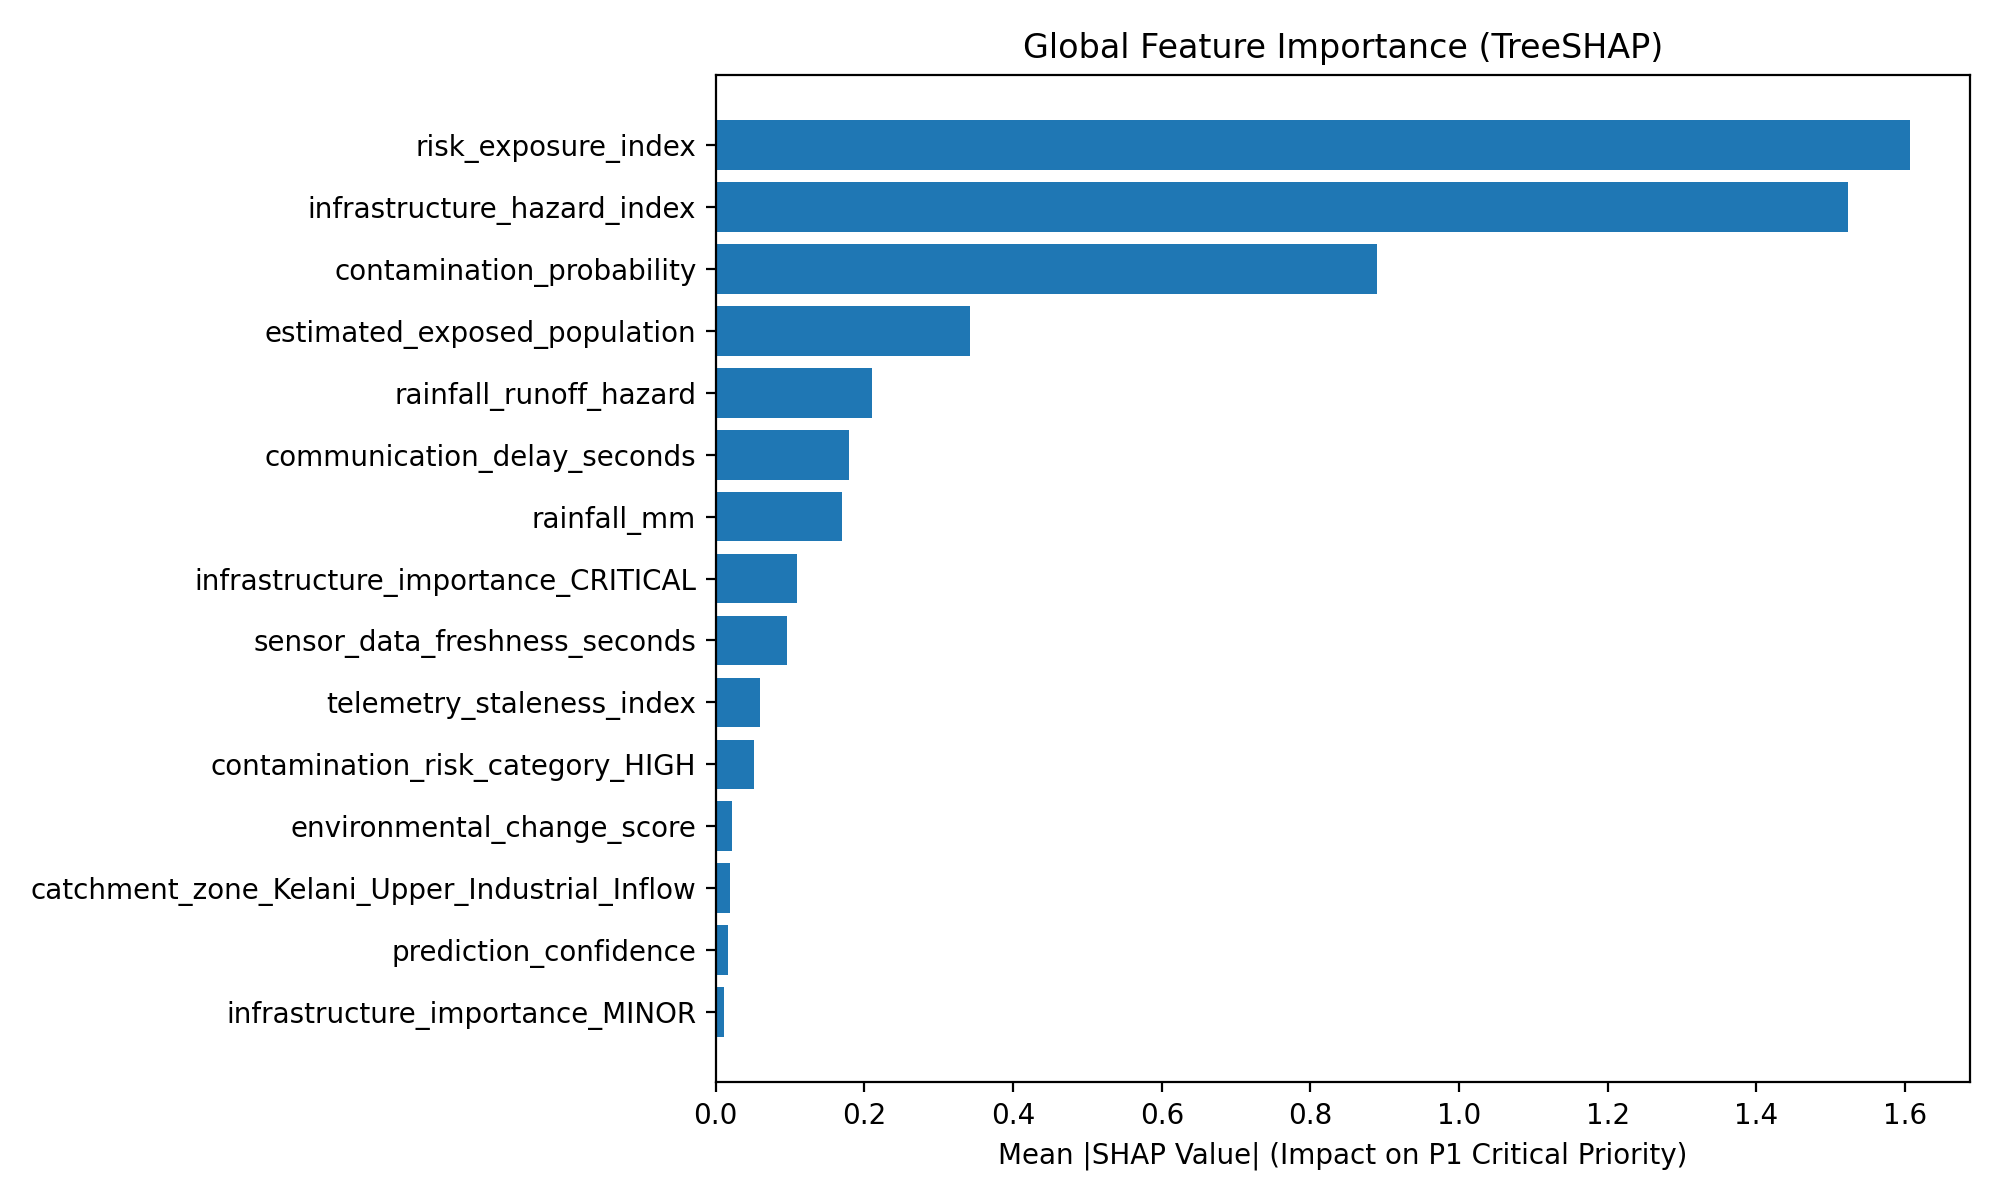

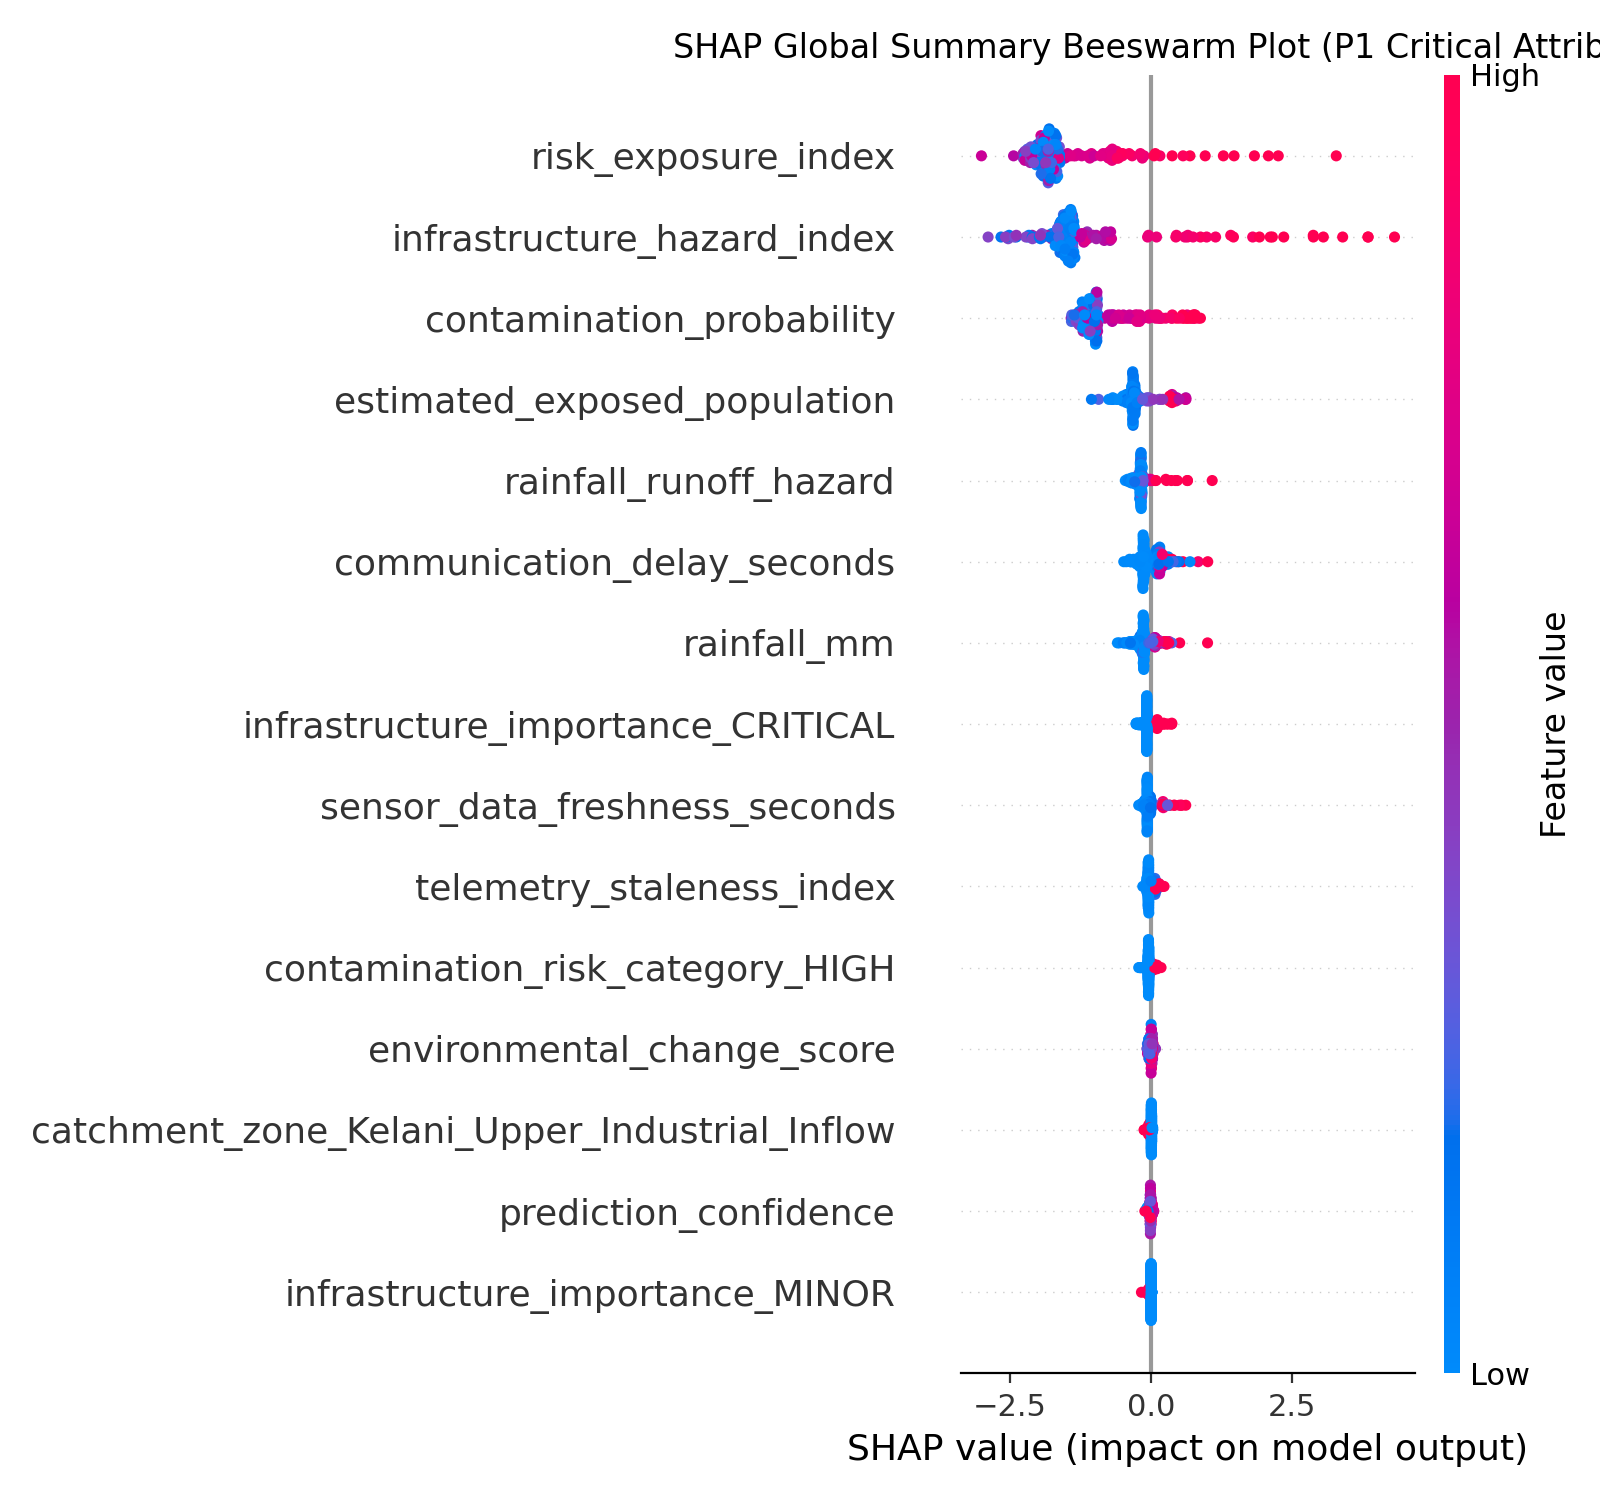

In [3]:
from IPython.display import Image, display

if bar_path.exists():
    display(Image(filename=str(bar_path)))

if beeswarm_path.exists():
    display(Image(filename=str(beeswarm_path)))


### Section 3: Local Instance Explanation (Scenario-Level)
**Source Module:** `src/component04_ml/explainability.py` -> `DecisionModelExplainer.explain_instance()`

#### Operational Decision Support in Action:
When an alert is dispatched to field operators or emergency coordinators, the system attaches the **Top-5 Driver Features** explaining the classification:
- **Positive Drivers ($+\phi$)**: Features pushing the decision toward the assigned class (e.g. Critical municipal intake, elevated contamination risk).
- **Negative Drivers ($-\phi$)**: Features mitigating the decision (e.g. alternative water supplies available).


In [4]:
sample_scen = test_df[test_df["priority_level"] == "P1"].iloc[0].to_dict()
sample_scaled = preprocessor.transform(pd.DataFrame([sample_scen]))[0]

drivers = explainer.explain_instance(
    x_scaled=sample_scaled,
    raw_feature_dict=sample_scen,
    target_class_idx=0,  # P1 Critical
    top_k=5
)

print(f"Local SHAP Explanation for Scenario: {sample_scen['scenario_id']}")
for d in drivers:
    print(f"  {d['feature']}: SHAP={d['shap_value']:+.4f} -> {d['impact']}")


Local SHAP Explanation for Scenario: SCEN_02767
  infrastructure_hazard_index: SHAP=+3.8427 -> INCREASES_PRIORITY
  contamination_probability: SHAP=+0.6416 -> INCREASES_PRIORITY
  infrastructure_importance_CRITICAL: SHAP=+0.3709 -> INCREASES_PRIORITY
  communication_delay_seconds: SHAP=+0.2307 -> INCREASES_PRIORITY
  estimated_exposed_population: SHAP=-0.2162 -> DECREASES_PRIORITY
